In [1]:
print("機械学習、始めます")

機械学習、始めます


In [2]:
v

NameError: name 'v' is not defined

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

raw = load_breast_cancer(as_frame=True)
X = raw.data
y = (raw.target == 0).astype(int)
names = list(X.columns)
Xdev, Xte, ydev, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
grid = GridSearchCV(lr, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                    cv=cv5, scoring="roc_auc").fit(Xdev, ydev)
print("開発用:", len(ydev), "／ テスト用（封をしている）:", len(yte))
print("選ばれた C:", grid.best_params_["logisticregression__C"], "／ 検証の AUC =", round(grid.best_score_, 4))

開発用: 455 ／ テスト用（封をしている）: 114
選ばれた C: 0.1 ／ 検証の AUC = 0.9944


In [4]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn import metrics as skm

oof = cross_val_predict(clone(grid.best_estimator_), Xdev, ydev, cv=cv5, method="predict_proba")[:, 1]
pred_v = (oof >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(ydev, pred_v).ravel()
print("TN, FP, FN, TP =", tn, fp, fn, tp)
own = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "sensitivity (recall)": tp / (tp + fn), "specificity": tn / (tn + fp),
       "precision (PPV)": tp / (tp + fp), "NPV": tn / (tn + fn)}
own["F1"] = 2 * own["precision (PPV)"] * own["sensitivity (recall)"] / (own["precision (PPV)"] + own["sensitivity (recall)"])
own["balanced accuracy"] = (own["sensitivity (recall)"] + own["specificity"]) / 2
lib = {"accuracy": skm.accuracy_score(ydev, pred_v), "sensitivity (recall)": skm.recall_score(ydev, pred_v),
       "specificity": skm.recall_score(ydev, pred_v, pos_label=0),
       "precision (PPV)": skm.precision_score(ydev, pred_v), "NPV": skm.precision_score(ydev, pred_v, pos_label=0),
       "F1": skm.f1_score(ydev, pred_v), "balanced accuracy": skm.balanced_accuracy_score(ydev, pred_v)}
print(pd.DataFrame({"own formula": own, "scikit-learn": lib}).round(4).to_string())
print("最大の差:", max(abs(own[k] - lib[k]) for k in own))

zero = np.zeros(len(ydev), dtype=int)
print(f"全部良性: 正解率 {skm.accuracy_score(ydev, zero):.3f}、感度 {skm.recall_score(ydev, zero):.3f}")

TN, FP, FN, TP = 284 1 9 161
                      own formula  scikit-learn
accuracy                   0.9780        0.9780
sensitivity (recall)       0.9471        0.9471
specificity                0.9965        0.9965
precision (PPV)            0.9938        0.9938
NPV                        0.9693        0.9693
F1                         0.9699        0.9699
balanced accuracy          0.9718        0.9718
最大の差: 0.0
全部良性: 正解率 0.626、感度 0.000


In [5]:
sens_v, spec_v = own["sensitivity (recall)"], own["specificity"]
ben, mal = np.where(ydev == 0)[0], np.where(ydev == 1)[0]
rows = []
for p in [ydev.mean(), 0.05, 0.01]:
    ppv_formula = sens_v * p / (sens_v * p + (1 - spec_v) * (1 - p))
    n_mal = int(round(p / (1 - p) * len(ben)))
    sim = []
    for seed in range(60):
        idx = np.r_[ben, np.random.default_rng(seed).choice(mal, n_mal, replace=False)]
        sim.append(skm.precision_score(ydev.iloc[idx], pred_v[idx], zero_division=0))
    rows.append((f"{p:.3f}", n_mal, round(ppv_formula, 3), round(float(np.mean(sim)), 3), round(1 - p, 3)))
print(pd.DataFrame(rows, columns=["prevalence", "malignant n", "PPV (formula)", "PPV (simulated)", "accuracy of 'all benign'"]).to_string(index=False))

prevalence  malignant n  PPV (formula)  PPV (simulated)  accuracy of 'all benign'
     0.374          170          0.994            0.994                     0.626
     0.050           15          0.934            0.934                     0.950
     0.010            3          0.732            0.740                     0.990


In [6]:
roc_full, ap_full = skm.roc_auc_score(ydev, oof), skm.average_precision_score(ydev, oof)
brier_own = np.mean((oof - ydev.values) ** 2)
print(f"全データ（悪性 37%）: ROC-AUC {roc_full:.4f}、AP {ap_full:.4f}、Brier {brier_own:.4f}（scikit-learn: {skm.brier_score_loss(ydev, oof):.4f}）")
for p in [0.05, 0.01]:
    n_mal = int(round(p / (1 - p) * len(ben)))
    r, a = [], []
    for seed in range(60):
        idx = np.r_[ben, np.random.default_rng(seed).choice(mal, n_mal, replace=False)]
        r.append(skm.roc_auc_score(ydev.iloc[idx], oof[idx])); a.append(skm.average_precision_score(ydev.iloc[idx], oof[idx]))
    print(f"悪性 {p:.0%}（{n_mal} 例）: ROC-AUC {np.mean(r):.4f}、AP {np.mean(a):.4f}（60 通りの平均）")

全データ（悪性 37%）: ROC-AUC 0.9946、AP 0.9933、Brier 0.0250（scikit-learn: 0.0250）
悪性 5%（15 例）: ROC-AUC 0.9926、AP 0.9648（60 通りの平均）
悪性 1%（3 例）: ROC-AUC 0.9939、AP 0.9580（60 通りの平均）


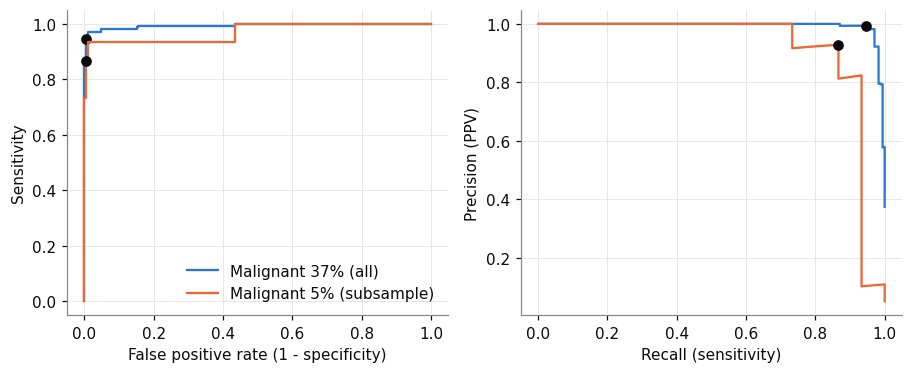

In [7]:
idx5 = np.r_[ben, np.random.default_rng(0).choice(mal, int(round(0.05 / 0.95 * len(ben))), replace=False)]
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.5))
for yy_, pp_, col, lab in [(ydev.values, oof, BLUE, "Malignant 37% (all)"), (ydev.values[idx5], oof[idx5], ORANGE, "Malignant 5% (subsample)")]:
    fpr, tpr, _ = skm.roc_curve(yy_, pp_); pr_, rc_, _ = skm.precision_recall_curve(yy_, pp_)
    axs[0].plot(fpr, tpr, color=col, label=lab); axs[1].plot(rc_, pr_, color=col, label=lab)
    tn_, fp_, fn_, tp_ = confusion_matrix(yy_, (pp_ >= 0.5).astype(int)).ravel()
    axs[0].plot(fp_ / (fp_ + tn_), tp_ / (tp_ + fn_), "o", color=INK)
    axs[1].plot(tp_ / (tp_ + fn_), tp_ / (tp_ + fp_), "o", color=INK)
axs[0].set_xlabel("False positive rate (1 - specificity)"); axs[0].set_ylabel("Sensitivity"); axs[0].legend(frameon=False, loc="lower right")
axs[1].set_xlabel("Recall (sensitivity)"); axs[1].set_ylabel("Precision (PPV)")
plt.tight_layout(); plt.show()

In [8]:
p = 0.02
print(sens_v * p / (sens_v * p + (1 - spec_v) * (1 - p)))

0.8463524854744993


In [9]:
yy_g, xx_g = np.ogrid[:128, :128]
def disk(r, dy=0):
    return (yy_g - 64 - dy) ** 2 + (xx_g - 64) ** 2 <= r * r

def dice(a, b):
    s = a.sum() + b.sum()
    return np.nan if s == 0 else 2 * np.logical_and(a, b).sum() / s

def iou(a, b):
    u = np.logical_or(a, b).sum()
    return np.nan if u == 0 else np.logical_and(a, b).sum() / u

a = disk(5)
print(dice(a, disk(5, 1)), dice(a, disk(5, 3)))

0.8641975308641975 0.6419753086419753


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

def r2_own(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

target = "mean area"
Xa, Xb, ya, yb = train_test_split(Xdev, Xdev[target], test_size=0.3, random_state=0)
f_all = [c for c in names if c != target]
f_weak = ["mean texture", "mean smoothness", "mean symmetry"]
models_r = {"predict the training mean": None,
            "linear: radius only": (LinearRegression(), ["mean radius"]),
            "linear: texture+smoothness+symmetry": (LinearRegression(), f_weak),
            "linear: all 29": (LinearRegression(),

_IncompleteInputError: incomplete input (2039312883.py, line 14)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

def r2_own(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

target = "mean area"
Xa, Xb, ya, yb = train_test_split(Xdev, Xdev[target], test_size=0.3, random_state=0)
f_all = [c for c in names if c != target]
f_weak = ["mean texture", "mean smoothness", "mean symmetry"]
models_r = {"predict the training mean": None,
            "linear: radius only": (LinearRegression(), ["mean radius"]),
            "linear: texture+smoothness+symmetry": (LinearRegression(), f_weak),
            "linear: all 29": (LinearRegression(), f_all),
            "decision tree: all 29": (DecisionTreeRegressor(random_state=0), f_all)}
rows = []
for name, spec_ in models_r.items():
    if spec_ is None:
        p_tr, p_va = np.full(len(ya), ya.mean()), np.full(len(yb), ya.mean())
    else:
        m, cols = spec_; m.fit(Xa[cols], ya); p_tr, p_va = m.predict(Xa[cols]), m.predict(Xb[cols])
    assert np.isclose(r2_own(yb.values, p_va), skm.r2_score(yb, p_va))
    rows.append((name, r2_own(ya.values, p_tr), r2_own(yb.values, p_va), skm.mean_absolute_error(yb, p_va), np.sqrt(np.mean((yb.values - p_va) ** 2))))
print(pd.DataFrame(rows, columns=["model", "R2 (train)", "R2 (validation)", "MAE", "RMSE"]).round(3).to_string(index=False))
print("検証の面積の平均:", round(yb.mean(), 1))
half = 0.5 * yb.values
print(f"予測 = 正解 × 0.5: r² = {np.corrcoef(yb.values, half)[0, 1] ** 2:.3f}、R² = {r2_own(yb.values, half):.3f}")

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

def r2_own(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

target = "mean area"
Xa, Xb, ya, yb = train_test_split(Xdev, Xdev[target], test_size=0.3, random_state=0)
f_all = [c for c in names if c != target]
f_weak = ["mean texture", "mean smoothness", "mean symmetry"]
models_r = {"predict the training mean": None,
            "linear: radius only": (LinearRegression(), ["mean radius"]),
            "linear: texture+smoothness+symmetry": (LinearRegression(), f_weak),
            "linear: all 29": (LinearRegression(), f_all),
            "decision tree: all 29": (DecisionTreeRegressor(random_state=0), f_all)}
rows = []
for name, spec_ in models_r.items():
    if spec_ is None:
        p_tr, p_va = np.full(len(ya), ya.mean()), np.full(len(yb), ya.mean())
    else:
        m, cols = spec_; m.fit(Xa[cols], ya); p_tr, p_va = m.predict(Xa[cols]), m.predict(Xb[cols])
    assert np.isclose(r2_own(yb.values, p_va), skm.r2_score(yb, p_va))
    rows.append((name, r2_own(ya.values, p_tr), r2_own(yb.values, p_va), skm.mean_absolute_error(yb, p_va), np.sqrt(np.mean((yb.values - p_va) ** 2))))
print(pd.DataFrame(rows, columns=["model", "R2 (train)", "R2 (validation)", "MAE", "RMSE"]).round(3).to_string(index=False))
print("検証の面積の平均:", round(yb.mean(), 1))
half = 0.5 * yb.values
print(f"予測 = 正解 × 0.5: r² = {np.corrcoef(yb.values, half)[0, 1] ** 2:.3f}、R² = {r2_own(yb.values, half):.3f}")

                              model  R2 (train)  R2 (validation)     MAE    RMSE
          predict the training mean       0.000           -0.022 271.995 376.352
                linear: radius only       0.974            0.972  40.841  62.631
linear: texture+smoothness+symmetry       0.147            0.126 248.112 348.102
                     linear: all 29       0.998            0.992  15.092  33.679
              decision tree: all 29       1.000            0.966  21.174  68.824
検証の面積の平均: 690.7
予測 = 正解 × 0.5: r² = 1.000、R² = -0.111


In [13]:
a, empty = disk(3), np.zeros((128, 128), dtype=bool)
print(f"何も塗らない: 画素の正解率 {(a == empty).mean():.4f}、Dice {dice(a, empty):.1f}")
print("正解も予測も空: Dice =", dice(empty, empty), "（0÷0。1 とみなすか、評価から外すかを、研究の前に決めて書く）")

何も塗らない: 画素の正解率 0.9982、Dice 0.0
正解も予測も空: Dice = nan （0÷0。1 とみなすか、評価から外すかを、研究の前に決めて書く）


In [14]:
print(round(skm.average_precision_score(ydev, pred_v), 4))

0.961


In [15]:
print(round(skm.average_precision_score(ydev, oof), 4))

0.9933


In [16]:
final = grid.best_estimator_
prob = final.predict_proba(Xte)[:, 1]
pred = (prob >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["true benign", "true malignant"], columns=["pred benign", "pred malignant"]))
sens, spec = tp / (tp + fn), tn / (tn + fp)
print(f"感度 {sens:.3f}（{tp}/{tp + fn}）／ 特異度 {spec:.3f}（{tn}/{tn + fp}）／ AUC {roc_auc_score(yte, prob):.4f}")

for lab, k, n_ in [("感度", tp, tp + fn), ("特異度", tn, tn + fp)]:
    ci = stats.binomtest(int(k), int(n_)).proportion_ci(confidence_level=0.95, method="wilson")
    print(f"{lab} の 95% 信頼区間（Wilson）: {ci.low:.3f}〜{ci.high:.3f}")
rng = np.random.default_rng(0)
aucs = []
for _ in range(2000):
    i = rng.integers(0, len(yte), len(yte))
    if yte.iloc[i].nunique() == 2: aucs.append(roc_auc_score(yte.iloc[i], prob[i]))
print(f"AUC の 95% 信頼区間（ブートストラップ）: {np.percentile(aucs, 2.5):.3f}〜{np.percentile(aucs, 97.5):.3f}")

                pred benign  pred malignant
true benign              71               1
true malignant            2              40
感度 0.952（40/42）／ 特異度 0.986（71/72）／ AUC 0.9917
感度 の 95% 信頼区間（Wilson）: 0.842〜0.987
特異度 の 95% 信頼区間（Wilson）: 0.925〜0.998
AUC の 95% 信頼区間（ブートストラップ）: 0.979〜1.000


In [17]:
for threshold in [0.5, 0.3, 0.1]:
    pred_t = (prob >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(yte, pred_t).ravel()
    print(f"しきい値 {threshold}: 感度 {tp_t/(tp_t+fn_t):.3f}、特異度 {tn_t/(tn_t+fp_t):.3f}")

しきい値 0.5: 感度 0.952、特異度 0.986
しきい値 0.3: 感度 0.952、特異度 0.875
しきい値 0.1: 感度 1.000、特異度 0.750


In [18]:
print(round(roc_auc_score(yte, final.predict(Xte)), 4))

0.9692


In [19]:
print(round(roc_auc_score(yte, final.predict_proba(Xte)[:, 1]), 4))


0.9917


In [20]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12]
tr, va = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0)
    tr.append(t.fit(Xdev, ydev).score(Xdev, ydev))
    va.append(cross_val_score(t, Xdev, ydev, cv=cv5).mean())
print(pd.DataFrame({"depth": depths, "training": np.round(tr, 3), "validation": np.round(va, 3)}).to_string(index=False))

 depth  training  validation
     1     0.923       0.899
     2     0.952       0.921
     3     0.976       0.932
     4     0.991       0.932
     5     0.996       0.934
     6     0.998       0.930
     8     1.000       0.927
    10     1.000       0.927
    12     1.000       0.927


In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0)
rf.fit(Xdev, ydev)
tr_rf = rf.score(Xdev, ydev)
va_rf = cross_val_score(rf, Xdev, ydev, cv=cv5).mean()
print(f"訓練: {tr_rf:.3f}、交差検証: {va_rf:.3f}、差: {tr_rf - va_rf:.3f}")

訓練: 1.000、交差検証: 0.954、差: 0.046
